EXPERIMENT NO. 11 (Group B) 
 
Aim: Data Aggregation 
Problem Statement: Analyzing Sales Performance by Region in a Retail Company 
Dataset: "Retail_Sales_Data.csv" 
Description: The dataset contains information about sales transactions in a retail company. It includes 
attributes such as transaction date, product category, quantity sold, and sales 
amount. The goal is to perform data aggregation to analyze the sales performance by region and identify 
the top-performing regions.



Name:Aditya Rade
Roll.No:BEAD23167

Outputs:

Step 1 — Import and Load Dataset

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("customer_shopping_data.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Shape: (99457, 10)


,invoice_no,customer_id,gender,age,category,quantity,price,payment_method,invoice_date,shopping_mall
0,I138884,C241288,Female,28,Clothing,5,1500.40,Credit Card,5/8/2022,Kanyon
1,I317333,C111565,Male,21,Shoes,3,1800.51,Debit Card,12/12/2021,Forum Istanbul
2,I127801,C266599,Male,20,Clothing,1,300.08,Cash,9/11/2021,Metrocity
3,I173702,C988172,Female,66,Shoes,5,3000.85,Credit Card,16/05/2021,Metropol AVM
4,I337046,C189076,Female,53,Books,4,60.60,Cash,24/10/2021,Kanyon


Step 2 — Explore and Clean Data

In [3]:
df.columns = df.columns.str.strip().str.lower().str.replace(" ", "_")

for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].astype(str).str.strip()

df["quantity"] = pd.to_numeric(df["quantity"], errors="coerce")
df["price"] = pd.to_numeric(df["price"], errors="coerce")

df = df.dropna(
    subset=["shopping_mall", "category", "quantity", "price"]
)

print("Columns:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

Columns:
['invoice_no', 'customer_id', 'gender', 'age', 'category', 'quantity', 'price', 'payment_method', 'invoice_date', 'shopping_mall']

Missing Values:
invoice_no        0
customer_id       0
gender            0
age               0
category          0
quantity          0
price             0
payment_method    0
invoice_date      0
shopping_mall     0
dtype: int64


Step 3 — Total Sales by Mall

In [4]:
df["sales_amount"] = df["price"] * df["quantity"]

branch_sales = (
    df.groupby("shopping_mall")["sales_amount"]
    .sum()
    .sort_values(ascending=False)
)

print("Total Sales by Shopping Mall:")
print(branch_sales)

print("\nTop Performing Mall:")
print(branch_sales.head(1))

Total Sales by Shopping Mall:
shopping_mall
Mall of Istanbul     50872481.68
Kanyon               50554231.10
Metrocity            37302787.33
Metropol AVM         25379913.19
Istinye Park         24618827.68
Zorlu Center         12901053.82
Cevahir AVM          12645138.20
Viaport Outlet       12521339.72
Emaar Square Mall    12406100.29
Forum Istanbul       12303921.24
Name: sales_amount, dtype: float64

Top Performing Mall:
shopping_mall
Mall of Istanbul    50872481.68
Name: sales_amount, dtype: float64


Step 4 — Sales Visualization

Sales by Category:
category
Clothing           1.139968e+08
Shoes              6.655345e+07
Technology         5.786235e+07
Cosmetics          6.792863e+06
Toys               3.980426e+06
Food & Beverage    8.495351e+05
Books              8.345529e+05
Souvenir           6.358247e+05
Name: sales_amount, dtype: float64


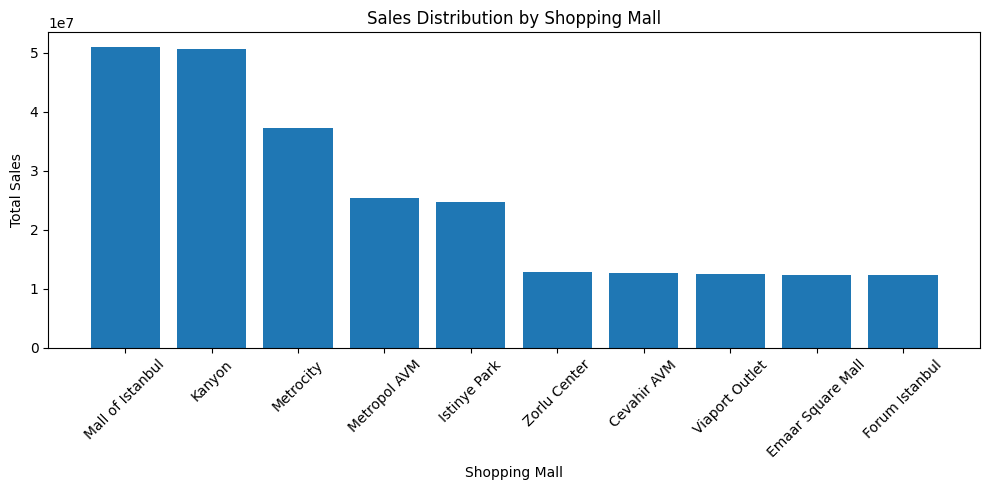

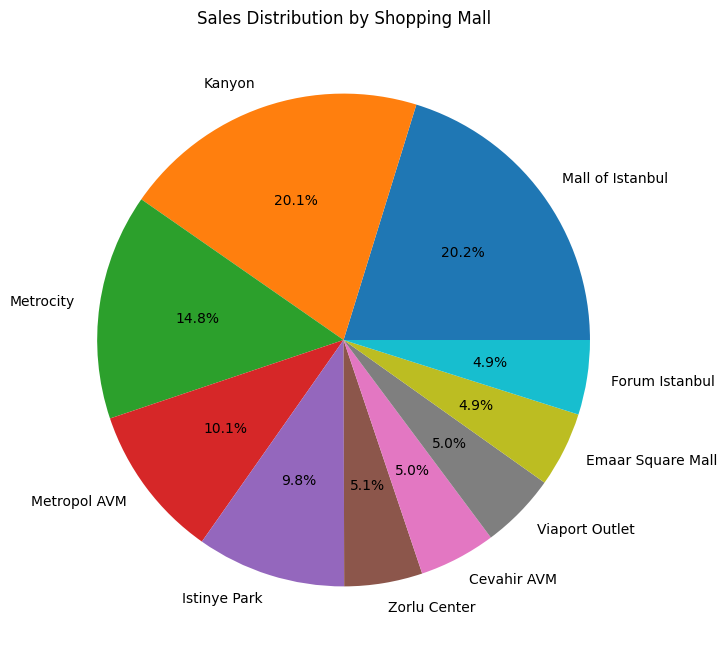

In [5]:
category_sales = (
    df.groupby("category")["sales_amount"]
    .sum()
    .sort_values(ascending=False)
)

print("Sales by Category:")
print(category_sales)

plt.figure(figsize=(10, 5))
plt.bar(branch_sales.index, branch_sales.values)

plt.xlabel("Shopping Mall")
plt.ylabel("Total Sales")
plt.title("Sales Distribution by Shopping Mall")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 8))
plt.pie(
    branch_sales.values,
    labels=branch_sales.index,
    autopct="%1.1f%%"
)

plt.title("Sales Distribution by Shopping Mall")
plt.show()

Step 5 — Mall + Category Aggregation

Sales by Mall and Category:


category,Books,Clothing,Cosmetics,Food & Beverage,Shoes,Souvenir,Technology,Toys
shopping_mall,,,,,,,,
Cevahir AVM,44541.00,5706321.28,321214.00,44010.45,3243918.85,29723.82,3051300.0,204108.80
Emaar Square Mall,41995.80,5590490.40,338941.76,40610.95,3089675.16,30943.74,3094350.0,179092.48
Forum Istanbul,42056.40,5792444.24,353172.76,39162.24,3327942.65,32879.19,2516850.0,199413.76
Istinye Park,76083.30,11253900.24,655357.88,85918.44,6641481.22,68925.48,5436900.0,400261.12
Kanyon,163029.15,22609527.60,1369550.78,166497.05,13383190.83,127399.53,11944800.0,790236.16
Mall of Istanbul,172240.35,22947417.68,1367517.78,171177.90,13467814.80,127540.29,11828250.0,790522.88
Metrocity,125911.65,17226692.56,991860.04,129902.74,9519296.37,94227.09,8608950.0,605946.88
Metropol AVM,83718.90,11568084.00,680770.38,88638.04,7149825.21,67869.78,5327700.0,413306.88
Viaport Outlet,39632.40,5604594.16,347439.70,41662.18,3194704.91,27319.17,3066000.0,199987.20


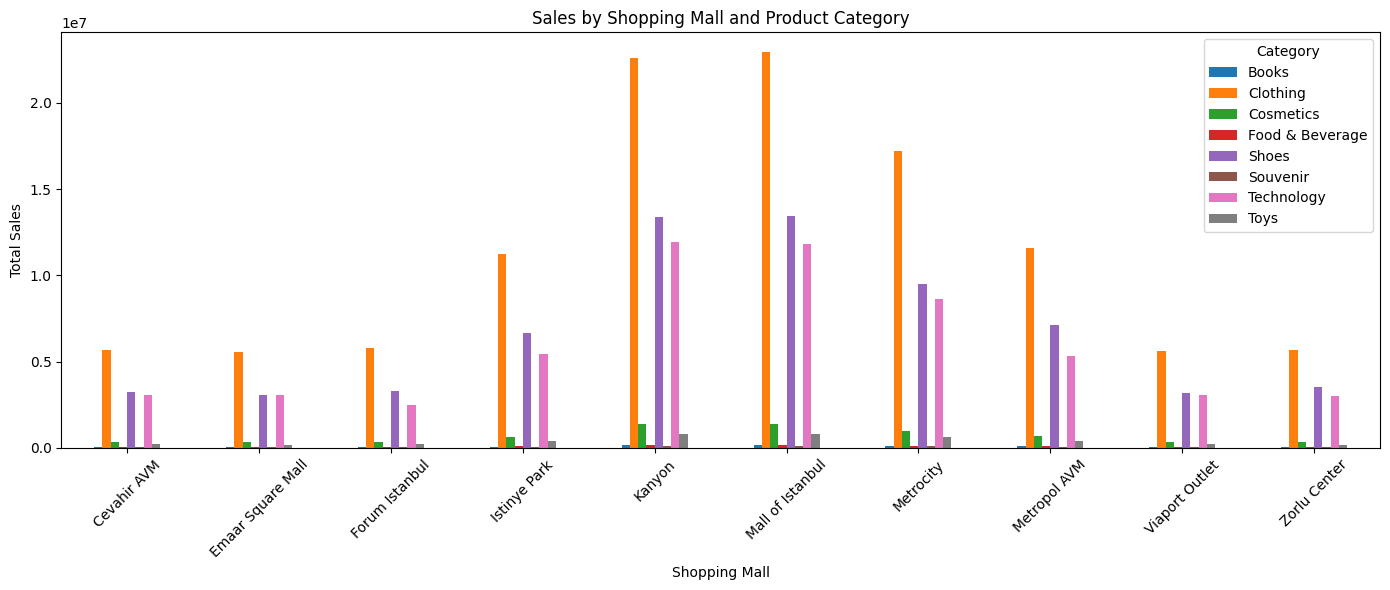


Top 5 Mall-Category Sales:
shopping_mall     category
Mall of Istanbul  Clothing    22947417.68
Kanyon            Clothing    22609527.60
Metrocity         Clothing    17226692.56
Mall of Istanbul  Shoes       13467814.80
Kanyon            Shoes       13383190.83
Name: sales_amount, dtype: float64
Aditya Rade  Roll.No:BEAD23167


In [7]:
combined_pivot = df.pivot_table(
    index="shopping_mall",
    columns="category",
    values="sales_amount",
    aggfunc="sum",
    fill_value=0
)

print("Sales by Mall and Category:")
display(combined_pivot)

combined_pivot.plot(
    kind="bar",
    figsize=(14, 6)
)

plt.xlabel("Shopping Mall")
plt.ylabel("Total Sales")
plt.title("Sales by Shopping Mall and Product Category")
plt.xticks(rotation=45)
plt.legend(title="Category")
plt.tight_layout()
plt.show()

print("\nTop 5 Mall-Category Sales:")
print(
    df.groupby(["shopping_mall", "category"])["sales_amount"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)


print("Aditya Rade  Roll.No:BEAD23167")